# 01 · Профиль данных

Все числа считаются из файлов `data/`, собранных ноутбуком `00_build_data.ipynb`.
Графики сохраняются в `figures/`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx

DATA, FIG = Path('data'), Path('figures')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Котировки

In [2]:
oh = pd.read_csv(DATA / 'history_ohlcv.csv', parse_dates=['TRADEDATE'])
tk = pd.read_csv(DATA / 'tickers.csv')
n, days = oh['SECID'].nunique(), oh['TRADEDATE'].nunique()
print(f'{len(oh):,} строк · {n} тикеров · {days} торговых дней '
      f'(с {oh.TRADEDATE.min().date()} по {oh.TRADEDATE.max().date()}) · заполненность панели {len(oh) / (n * days):.1%}')
tk['SECTOR'].value_counts().rename('тикеров').to_frame().T

35,754 строк · 46 тикеров · 873 торговых дней (с 2022-08-01 по 2025-12-30) · заполненность панели 89.0%


SECTOR,Financials,Metals & Mining,Oil & Gas,Other,Consumer,Electric Utilities,Telecom,Chemicals,Real Estate,IT & Innovation
тикеров,10,9,9,8,3,2,2,1,1,1


Панель несбалансированная: часть эмитентов вышла на торги позже августа 2022 года или имела
перерывы в котировании. Состав индекса взят на декабрь 2025 года, это survivorship bias.

## Новости

In [3]:
raw = pd.read_csv(DATA / 'news_aug2022_dec2025.csv', usecols=['channel', 'date'])
uniq = pd.read_csv(DATA / 'news_embeddings_index.csv')
print(f'сырых сообщений {len(raw):,} → после дедупликации {len(uniq):,} (удалено {len(raw) - len(uniq)})')
print(uniq['channel'].value_counts().to_string())

levels = pd.concat(pd.read_csv(DATA / 'news_linked.csv', usecols=['news_id', 'level'], chunksize=2_000_000))
t = levels.groupby('level').agg(новостей=('news_id', 'nunique'), связей=('news_id', 'size'))
t['доля новостей'] = (t['новостей'] / t['новостей'].sum()).round(3)
t['доля связей'] = (t['связей'] / t['связей'].sum()).round(3)
t['связей на новость'] = (t['связей'] / t['новостей']).round(1)
t.index = ['L1 · явный тикер (w = 1)', 'L2 · сектор (w = 0,5)', 'L3 · весь индекс (w = 0,2)']
t

сырых сообщений 23,027 → после дедупликации 22,345 (удалено 682)
channel
bcs_express     10995
smartlabnews     5843
RBCinvest        5507


,новостей,связей,доля новостей,доля связей,связей на новость
L1 · явный тикер (w = 1),9983,22970,0.447,0.048,2.3
"L2 · сектор (w = 0,5)",2921,24949,0.131,0.052,8.5
"L3 · весь индекс (w = 0,2)",9441,434286,0.423,0.901,46.0


Уровни взаимоисключающие. Явная привязка покрывает почти половину новостей, но 90 % всех
связей даёт широковещательный уровень L3: каждая макро-новость приписывается всем 46 тикерам.

## Признаки узла

In [4]:
X = np.load(DATA / 'node_features.npy', mmap_mode='r')
idx = pd.read_csv(DATA / 'node_features_index.csv')
print(f'матрица {X.shape[0]:,} × {X.shape[1]}: 5 лагов доходности, log-объём, has_news, 768 ruBERT')
print(f'has_news = 1 на {idx.has_news.mean():.2%} строк: флаг вырожден (следствие уровня L3)')

# сколько в эмбеддинге узла общерыночной моды: e_it = m_t + u_it, где m_t среднее по тикерам в день t
E = np.asarray(X[:, 7:], dtype=np.float64)
codes, cnt = pd.factorize(idx['TRADEDATE'])[0], None
cnt = np.bincount(codes)
M = np.zeros((len(cnt), E.shape[1])); np.add.at(M, codes, E); M /= cnt[:, None]
between = (((M - E.mean(0)) ** 2) * cnt[:, None]).sum() / ((E - E.mean(0)) ** 2).sum()
print(f'доля дисперсии эмбеддингов, объясняемая средним по рынку в этот день: {between:.1%}; '
      f'кросс-секционная (между тикерами внутри дня): {1 - between:.1%}')

матрица 35,202 × 775: 5 лагов доходности, log-объём, has_news, 768 ruBERT
has_news = 1 на 99.89% строк: флаг вырожден (следствие уровня L3)


доля дисперсии эмбеддингов, объясняемая средним по рынку в этот день: 64.7%; кросс-секционная (между тикерами внутри дня): 35.3%


Почти две трети дисперсии новостного признака приходится на общее для всех бумаг состояние дня, и лишь
треть различает бумаги между собой. Это важно для интерпретации результатов: новости
здесь в первую очередь индикатор рынка, а не отдельного эмитента.

## Граф эмитентов

40 месячных графов (2022-10 … 2026-01); на торговые дни выборки действуют 39
дерево (рёбер = узлов − 1) во всех графах: True
доля отрицательных рёбер: среднее 0.503, диапазон 0.405–0.641; месяцев ниже 0,40: 0


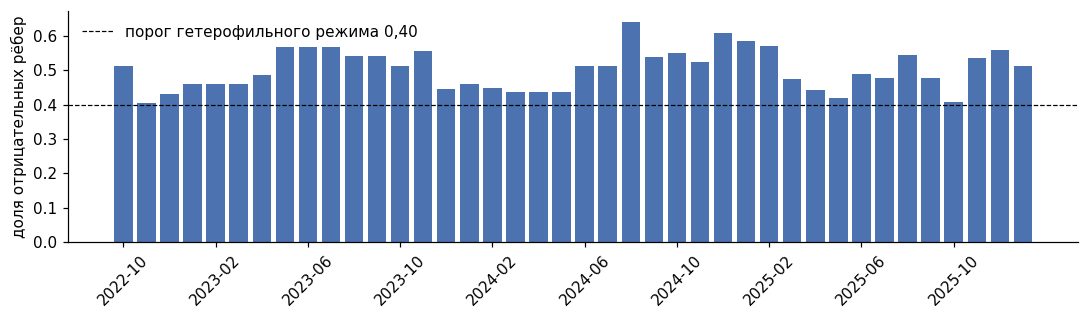

In [5]:
meta = pd.read_csv(DATA / 'graph_meta.csv')
d2m = pd.read_csv(DATA / 'date_to_month.csv')
neg = meta['n_neg'] / meta['n_edges']
print(f'{len(meta)} месячных графов ({meta.month_bucket.iloc[0]} … {meta.month_bucket.iloc[-1]}); '
      f'на торговые дни выборки действуют {d2m.month_bucket.nunique()}')
print(f'дерево (рёбер = узлов − 1) во всех графах: {(meta.n_edges == meta.n_active_nodes - 1).all()}')
print(f'доля отрицательных рёбер: среднее {neg.mean():.3f}, диапазон {neg.min():.3f}–{neg.max():.3f}; '
      f'месяцев ниже 0,40: {(neg < 0.4).sum()}')

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(meta['month_bucket'], neg, color='#4C72B0')
ax.axhline(0.4, ls='--', c='k', lw=0.8, label='порог гетерофильного режима 0,40')
ax.set_ylabel('доля отрицательных рёбер'); ax.set_xticks(ax.get_xticks()[::4]); ax.tick_params(axis='x', rotation=45)
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / 'graph_negative_share.png'); plt.show()

граф 2025-12: 44 активных узлов из 46, 43 рёбер, медианная степень 2, максимальная 6, хабы: PHOR, AFLT, CNRU, PLZL, TATN


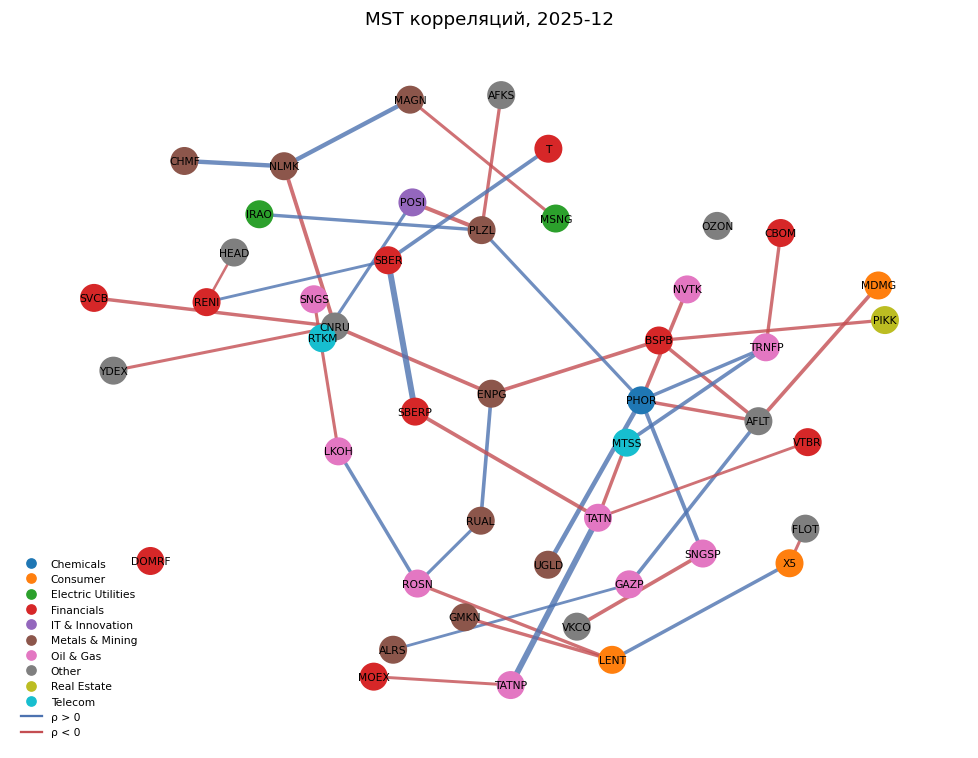

In [6]:
edges = pd.read_csv(DATA / 'graph_edges_corr.csv')
nodes = pd.read_csv(DATA / 'graph_nodes.csv')
last = d2m['month_bucket'].max()                                  # последний месяц, действующий на данные
e = edges[edges['month_bucket'] == last]
G = nx.Graph()
G.add_nodes_from(nodes['node_id'])
G.add_edges_from(zip(e['src'], e['dst']))
deg = pd.Series(dict(G.degree()))
hubs = nodes.set_index('node_id').loc[deg.nlargest(5).index, 'SECID'].tolist()
print(f'граф {last}: {(deg > 0).sum()} активных узлов из {G.number_of_nodes()}, {G.number_of_edges()} рёбер, '
      f'медианная степень {deg[deg > 0].median():.0f}, максимальная {deg.max()}, хабы: {", ".join(hubs)}')

sectors = sorted(nodes['SECTOR'].unique()); palette = plt.get_cmap('tab10')
color = {s: palette(i) for i, s in enumerate(sectors)}
pos = nx.spring_layout(G, seed=42, k=0.6)
fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(G, pos, ax=ax, width=[1 + 3 * a for a in e['abs_corr']],
                       edge_color=['#C44E52' if s < 0 else '#4C72B0' for s in e['sign']], alpha=0.8)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=300, node_color=[color[s] for s in nodes['SECTOR']])
nx.draw_networkx_labels(G, pos, labels=dict(zip(nodes['node_id'], nodes['SECID'])), ax=ax, font_size=7)
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=color[s], label=s) for s in sectors] +
                  [plt.Line2D([], [], color='#4C72B0', label='ρ > 0'), plt.Line2D([], [], color='#C44E52', label='ρ < 0')],
          fontsize=7, loc='lower left', frameon=False)
ax.set_title(f'MST корреляций, {last}'); ax.axis('off'); fig.tight_layout(); fig.savefig(FIG / 'mst_last_month.png'); plt.show()

Красные рёбра показывают отрицательные корреляции остатков после вычитания рыночной моды. Их около
половины в каждом месяце: это тот гетерофильный режим, ради которого выбрана sheaf-архитектура.

## Таргет и фолды

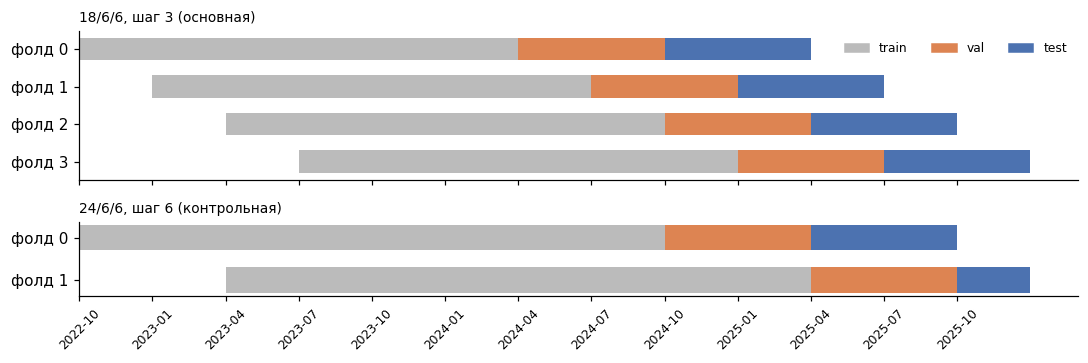

,фолд,тест,строк,DOWN,FLAT,UP
0,0,2024-10…2025-03,5455,39.6%,26.9%,33.5%
1,1,2025-01…2025-06,5447,37.3%,30.2%,32.6%
2,2,2025-04…2025-09,5730,35.2%,34.0%,30.8%
3,3,2025-07…2025-12,5818,33.8%,34.8%,31.3%


In [7]:
def make_folds(months, train=18, val=6, test=6, step=3, min_tail=6):
    folds, s = [], 0
    while True:
        tr, va, te = (months[s:s + train], months[s + train:s + train + val],
                      months[s + train + val:s + train + val + test])
        if len(tr) < train or len(va) < min_tail or len(te) < min_tail:
            return folds
        folds.append((tr, va, te)); s += step


idx['month'] = idx['TRADEDATE'].str[:7]
months = sorted(m for m in idx['month'].unique() if m in set(meta['month_bucket']))
grids = {'18/6/6, шаг 3 (основная)': make_folds(months), '24/6/6, шаг 6 (контрольная)': make_folds(months, 24, step=6, min_tail=3)}

fig, axes = plt.subplots(2, 1, figsize=(10, 3.4), sharex=True, gridspec_kw={'height_ratios': [4, 2]})
for ax, (name, folds) in zip(axes, grids.items()):
    for i, parts in enumerate(folds):
        for part, c in zip(parts, ['#BBBBBB', '#DD8452', '#4C72B0']):
            ax.barh(i, len(part), left=months.index(part[0]), color=c, height=0.6)
    ax.set_yticks(range(len(folds))); ax.set_yticklabels([f'фолд {i}' for i in range(len(folds))]); ax.invert_yaxis()
    ax.set_title(name, fontsize=9, loc='left')
axes[-1].set_xticks(range(0, len(months), 3)); axes[-1].set_xticklabels(months[::3], rotation=45, fontsize=8)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ['#BBBBBB', '#DD8452', '#4C72B0']],
               labels=['train', 'val', 'test'], ncol=3, fontsize=8, frameon=False, loc='upper right')
fig.tight_layout(); fig.savefig(FIG / 'folds.png'); plt.show()

# распределение классов на тесте: терцили по тикеру считаются только на train фолда
rows = []
for i, (tr, va, te) in enumerate(grids['18/6/6, шаг 3 (основная)']):
    q = idx[idx['month'].isin(tr)].groupby('SECID')['FUTURE_RETURN'].quantile([.33, .66]).unstack()
    t = idx[idx['month'].isin(te)]
    y = np.where(t['FUTURE_RETURN'] < t['SECID'].map(q[.33]), 0, np.where(t['FUTURE_RETURN'] > t['SECID'].map(q[.66]), 2, 1))
    rows.append(dict(фолд=i, тест=f'{te[0]}…{te[-1]}', строк=len(t), **{k: f'{v:.1%}' for k, v in zip(['DOWN', 'FLAT', 'UP'], np.bincount(y, minlength=3) / len(y))}))
pd.DataFrame(rows)

На train классы равны по построению, на тесте доли сдвигаются вместе с рынком: в падающие
полугодия растёт доля DOWN. Тестовые окна соседних фолдов пересекаются на три месяца;
это учитывается в тестах значимости в `03_results.ipynb`.